# Day 1 · Notebook 1 — Two-view geometry: the engine inside visual SLAM

Every visual SLAM / SfM system (ORB-SLAM, COLMAP, ...) repeats the same small loop:

1. **Project**: how does a 3D point land on the image? (camera model)
2. **Detect & describe** distinctive points in each image (features)
3. **Match** them between images
4. **Reject wrong matches** with geometry + RANSAC
5. **Recover the relative camera motion** $(R, t)$
6. **Triangulate** the matched points into 3D

We do all six on real images, step by step. Runs on CPU.

| Data | Used for |
|---|---|
| Sacre Coeur photos (from the hloc repo) | features, matching, RANSAC, epipolar lines |
| 17 frames from TUM RGB-D `fr3/long_office_household` (calibrated camera) | relative pose + triangulation |

In [1]:
# Colab already has numpy / opencv / matplotlib / plotly. Locally: pip install -r requirements.txt
import shutil, subprocess, time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

print("OpenCV", cv2.__version__)

# Use the local data/ folder if it exists (laptop), otherwise download from GitHub (Colab).
DATA = next((p for p in [Path("data"), Path("../data")] if p.exists()), Path("data"))

def sh(cmd):
    subprocess.run(cmd, shell=True, check=True)

def get_sacre_coeur():
    d = DATA / "sacre_coeur"
    if not (d / "mapping").exists():
        sh("git clone -q --depth 1 https://github.com/cvg/Hierarchical-Localization /tmp/hloc_repo")
        sh("git clone -q --depth 1 https://github.com/cvg/LightGlue /tmp/lightglue_repo")
        shutil.copytree("/tmp/hloc_repo/datasets/sacre_coeur/mapping", d / "mapping")
        (d / "query").mkdir(parents=True, exist_ok=True)
        shutil.copy("/tmp/lightglue_repo/assets/sacre_coeur1.jpg", d / "query/query_1.jpg")
        shutil.copy("/tmp/lightglue_repo/assets/sacre_coeur2.jpg", d / "query/query_2.jpg")
    return d

def get_tum():
    d = DATA / "tum_fr3_office" / "rgb"
    if not d.exists():
        sh("git clone -q --depth 1 --filter=blob:none --sparse "
           "https://github.com/magicleap/SuperGluePretrainedNetwork /tmp/sg_repo")
        sh("git -C /tmp/sg_repo sparse-checkout set assets/freiburg_sequence")
        shutil.copytree("/tmp/sg_repo/assets/freiburg_sequence", d)
    return d

SC = get_sacre_coeur()
TUM = get_tum()
print(sorted(p.name for p in (SC / "mapping").iterdir()))
print(len(list(TUM.iterdir())), "TUM frames")

OpenCV 4.13.0
['02928139_3448003521.jpg', '03903474_1471484089.jpg', '10265353_3838484249.jpg', '17295357_9106075285.jpg', '32809961_8274055477.jpg', '44120379_8371960244.jpg', '51091044_3486849416.jpg', '60584745_2207571072.jpg', '71295362_4051449754.jpg', '93341989_396310999.jpg']
17 TUM frames


## 1 · The pinhole camera

A 3D point $\mathbf{X}_w$ (world frame) is moved into the camera frame and then projected:

$$
\mathbf{X}_c = R\,\mathbf{X}_w + \mathbf{t},
\qquad
\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}
= K \,\mathbf{X}_c ,
\qquad
K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}
$$

Written compactly: $\lambda\,\tilde{\mathbf{x}} = K\,[R \mid \mathbf{t}]\,\tilde{\mathbf{X}}_w = P\,\tilde{\mathbf{X}}_w$ ($P$ is the $3\times4$ projection matrix).

* $K$ (**intrinsics**): focal length in pixels and principal point. Fixed for a camera, found by calibration.
* $R, \mathbf{t}$ (**extrinsics**): where the camera is. This is what SLAM estimates.
* $\lambda = Z_c$ is the depth. **Dividing by depth throws it away**, which is why one image can't give you 3D.

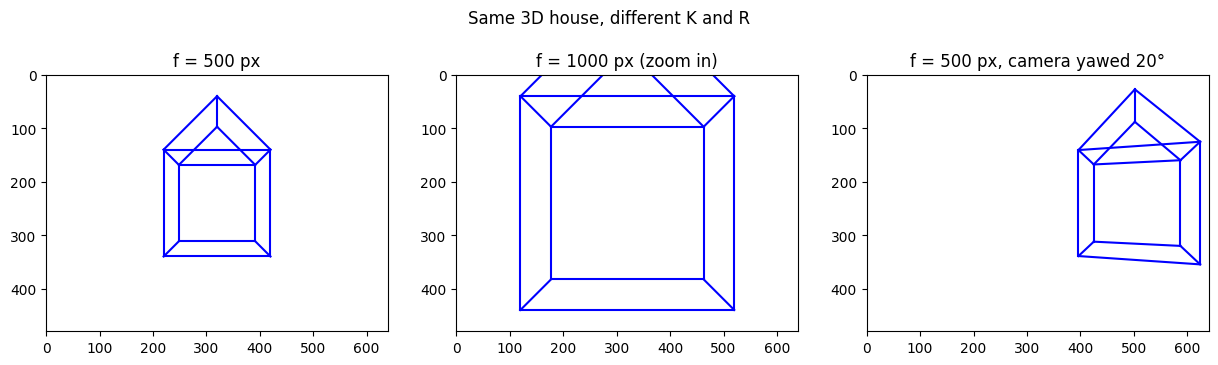

In [2]:
def project(X_w, K, R, t):
    """World points (N,3) -> pixels (N,2) and depths (N,)."""
    X_c = (R @ X_w.T + t.reshape(3, 1)).T
    uvw = (K @ X_c.T).T
    return uvw[:, :2] / uvw[:, 2:3], X_c[:, 2]

def rot_y(deg):
    a = np.radians(deg)
    return np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])

# A wireframe "house" 5 m in front of the camera
house = np.array([[-1, 1, 5], [1, 1, 5], [1, -1, 5], [-1, -1, 5], [0, -2, 5],     # front face + roof tip
                  [-1, 1, 7], [1, 1, 7], [1, -1, 7], [-1, -1, 7], [0, -2, 7]], float)
edges = [(0,1),(1,2),(2,3),(3,0),(2,4),(3,4),(5,6),(6,7),(7,8),(8,5),(7,9),(8,9),(0,5),(1,6),(2,7),(3,8),(4,9)]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (f, yaw, title) in zip(axs, [(500, 0, "f = 500 px"), (1000, 0, "f = 1000 px (zoom in)"),
                                     (500, 20, "f = 500 px, camera yawed 20°")]):
    K = np.array([[f, 0, 320], [0, f, 240], [0, 0, 1.0]])
    R = rot_y(yaw); t = np.zeros(3)
    uv, z = project(house, K, R, t)
    for i, j in edges:
        ax.plot(uv[[i, j], 0], uv[[i, j], 1], "b-")
    ax.set_xlim(0, 640); ax.set_ylim(480, 0); ax.set_aspect("equal"); ax.set_title(title)
plt.suptitle("Same 3D house, different K and R"); plt.show()

## 2 · Features: points we can find again

A **keypoint** is a location that is easy to find again (a corner or blob). A **descriptor** is a vector that describes the patch around it, so the *same* 3D point gives *similar* vectors in different images.

| | SIFT (Lowe 2004) | ORB (Rublee 2011) |
|---|---|---|
| Descriptor | 128-D float (gradient histograms) | 256-bit binary |
| Distance | L2 | Hamming (very fast) |
| Invariance | scale + rotation, quite robust | scale (pyramid) + rotation |
| Used by | COLMAP | ORB-SLAM (real-time) |

Learned features (SuperPoint, ALIKED, DISK) + learned matchers (SuperGlue, LightGlue) do the same job more robustly. We'll use them in Day 2 (hloc).

SIFT: 4000 keypoints, descriptor 128 x float32, 174 ms
ORB: 4000 keypoints, descriptor 32 x uint8, 447 ms


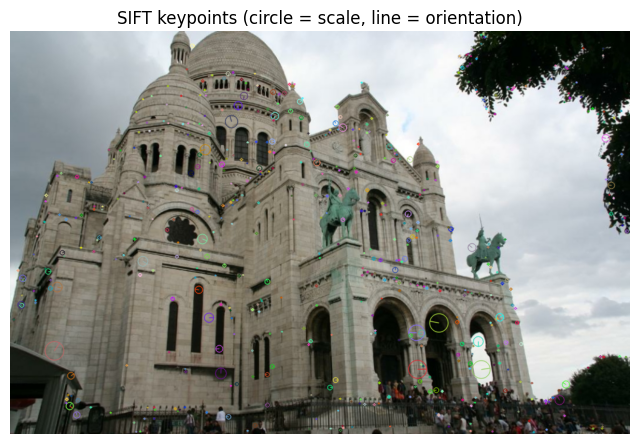

In [3]:
def load_gray(path, max_side=1024):
    img = cv2.imread(str(path))
    s = max_side / max(img.shape[:2])
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

rgb1, img1 = load_gray(SC / "mapping/10265353_3838484249.jpg")
rgb2, img2 = load_gray(SC / "mapping/60584745_2207571072.jpg")

sift = cv2.SIFT_create(nfeatures=4000)
orb = cv2.ORB_create(nfeatures=4000)

for name, det in [("SIFT", sift), ("ORB", orb)]:
    t0 = time.time(); kp, des = det.detectAndCompute(img1, None)
    print(f"{name}: {len(kp)} keypoints, descriptor {des.shape[1]} x {des.dtype}, {1000*(time.time()-t0):.0f} ms")

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

subset = [kp1[i] for i in np.random.default_rng(0).choice(len(kp1), 600, replace=False)]
vis = cv2.drawKeypoints(rgb1, subset, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(8, 8)); plt.imshow(vis); plt.title("SIFT keypoints (circle = scale, line = orientation)")
plt.axis("off"); plt.show()

## 3 · Matching and Lowe's ratio test

For each descriptor in image 1, find its **two** nearest neighbours $d_1 \le d_2$ in image 2. Keep the match only if

$$ \frac{d_1}{d_2} < 0.75 $$

If the best match is not clearly better than the second best, the point is ambiguous (repeated windows, sky, ...), so we drop it.

nearest neighbour: 4000 matches  ->  after ratio test: 811


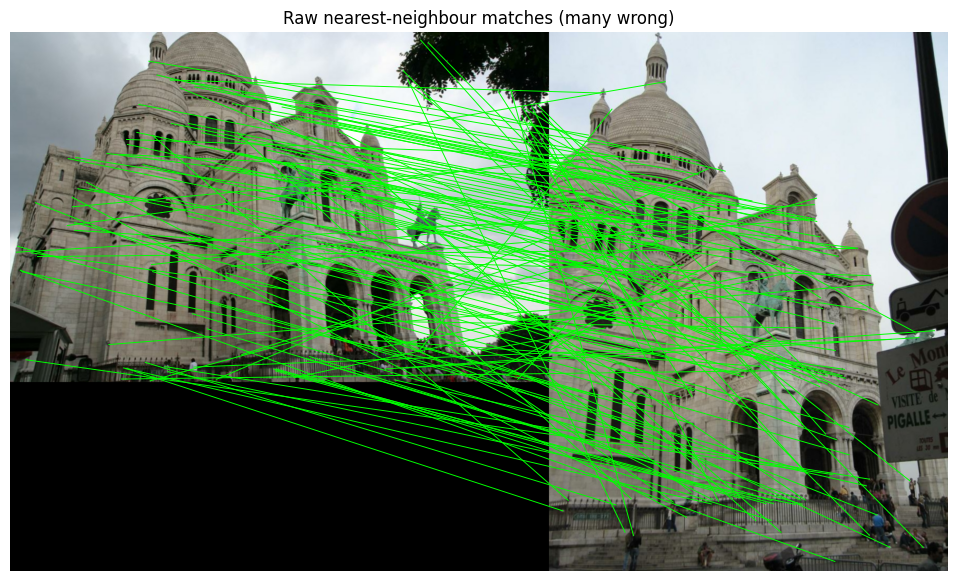

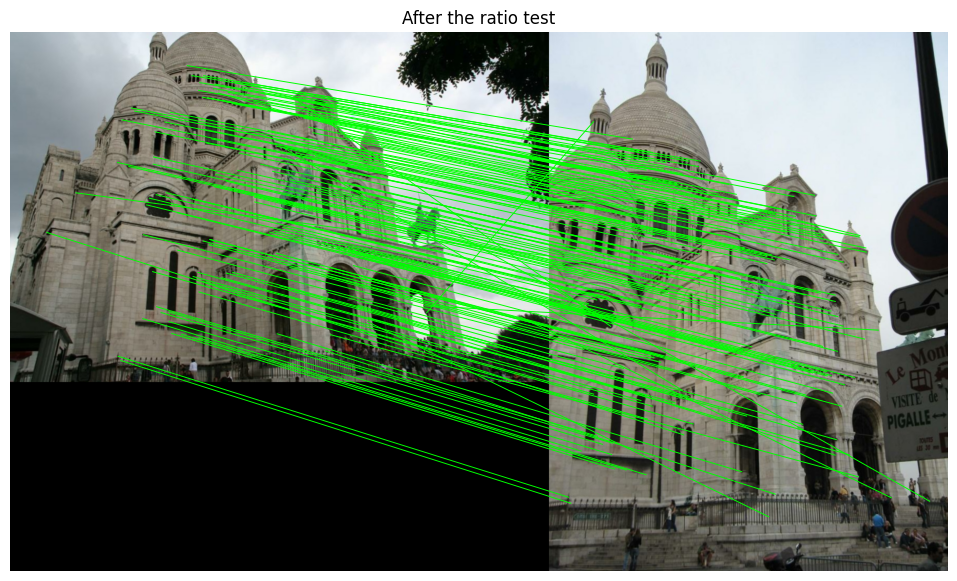

In [4]:
bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(des1, des2, k=2)
raw = [m for m, n in knn]
good = [m for m, n in knn if m.distance < 0.75 * n.distance]
print(f"nearest neighbour: {len(raw)} matches  ->  after ratio test: {len(good)}")

def draw_matches(matches, mask=None, n=150, title=""):
    rng = np.random.default_rng(0)
    idx = rng.choice(len(matches), min(n, len(matches)), replace=False)
    h = max(rgb1.shape[0], rgb2.shape[0])
    canvas = np.zeros((h, rgb1.shape[1] + rgb2.shape[1], 3), np.uint8)
    canvas[:rgb1.shape[0], :rgb1.shape[1]] = rgb1
    canvas[:rgb2.shape[0], rgb1.shape[1]:] = rgb2
    plt.figure(figsize=(16, 7)); plt.imshow(canvas)
    for i in idx:
        m = matches[i]
        (x1, y1), (x2, y2) = kp1[m.queryIdx].pt, kp2[m.trainIdx].pt
        c = "lime" if mask is None or mask[i] else "red"
        plt.plot([x1, x2 + rgb1.shape[1]], [y1, y2], "-", color=c, lw=0.7)
    plt.title(title); plt.axis("off"); plt.show()

draw_matches(raw, title="Raw nearest-neighbour matches (many wrong)")
draw_matches(good, title="After the ratio test")

## 4 · Epipolar geometry and RANSAC

A point $\mathbf{x}_1$ in image 1 can be anywhere along its viewing ray. Seen from camera 2, that ray is a line, the **epipolar line** $\mathbf{l}_2 = F\mathbf{x}_1$. The correct match must lie on it:

$$ \tilde{\mathbf{x}}_2^\top F \, \tilde{\mathbf{x}}_1 = 0 \qquad (F:\ 3\times3,\ \text{rank } 2,\ 7 \text{ DOF}) $$

$F$ (**fundamental matrix**) needs no calibration. If we know $K$, we work with normalised coordinates and get the **essential matrix**

$$ E = K_2^\top F K_1 = [\mathbf{t}]_\times R \qquad (5 \text{ DOF: 3 rotation} + 2 \text{ translation direction}) $$

**RANSAC** (Fischler & Bolles 1981):
1. pick a minimal random sample (8 matches for $F$ with the 8-point algorithm, 5 for $E$)
2. fit the model
3. count **inliers** (matches within ~1–3 px of their epipolar line)
4. repeat, keep the model with the most inliers

How many iterations? If a fraction $w$ of matches are inliers and we want success probability $p$:

$$ N = \frac{\log(1-p)}{\log\!\left(1-w^{s}\right)} $$

This is why **minimal** solvers (small $s$) matter.

iterations needed (p = 0.99)
inlier ratio |   s=3 (P3P)   s=5 (E)   s=8 (F)
    0.9     |         4         6         9
    0.7     |        11        26        78
    0.5     |        35       146      1177
    0.3     |       169      1893     70188

RANSAC kept 667 / 811 matches as inliers (82%)


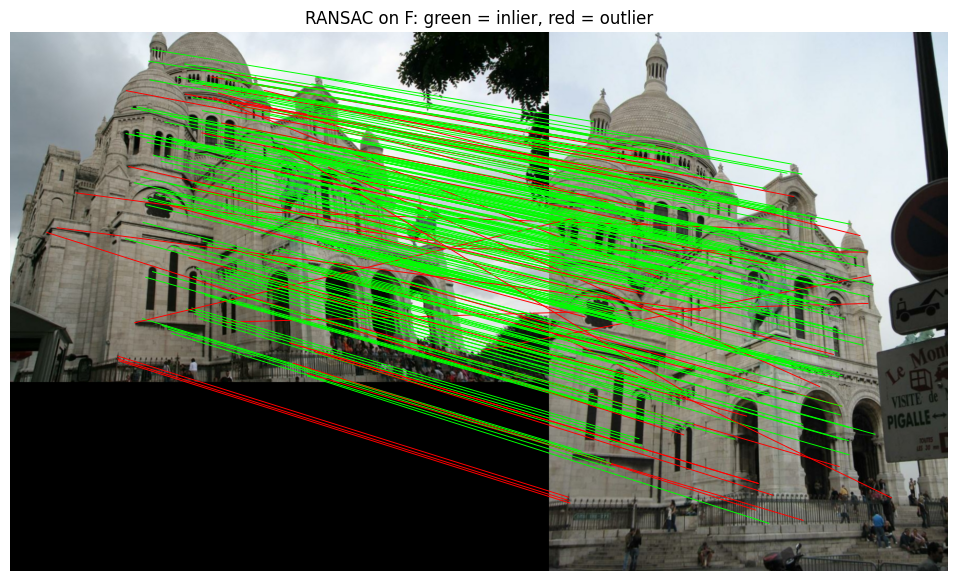

In [5]:
def ransac_iters(w, s, p=0.99):
    return int(np.ceil(np.log(1 - p) / np.log(1 - w ** s)))

print("iterations needed (p = 0.99)")
print("inlier ratio |   s=3 (P3P)   s=5 (E)   s=8 (F)")
for w in [0.9, 0.7, 0.5, 0.3]:
    print(f"    {w:.1f}     | {ransac_iters(w,3):9d} {ransac_iters(w,5):9d} {ransac_iters(w,8):9d}")

pts1 = np.float32([kp1[m.queryIdx].pt for m in good])
pts2 = np.float32([kp2[m.trainIdx].pt for m in good])
F, mask = cv2.findFundamentalMat(pts1, pts2, cv2.FM_RANSAC, ransacReprojThreshold=1.5, confidence=0.999)
mask = mask.ravel().astype(bool)
print(f"\nRANSAC kept {mask.sum()} / {len(good)} matches as inliers ({100*mask.mean():.0f}%)")
draw_matches(good, mask, n=250, title="RANSAC on F: green = inlier, red = outlier")

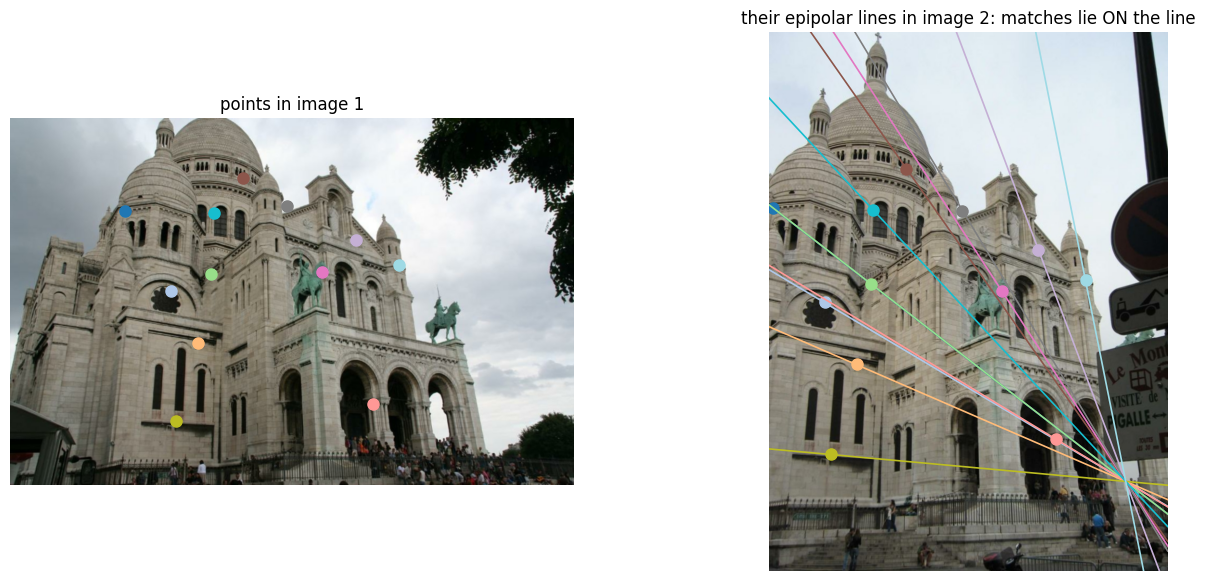

In [6]:
# Epipolar lines: pick some inliers in image 1 and draw l2 = F x1 in image 2.
sel = np.where(mask)[0][::max(1, mask.sum() // 12)][:12]
lines2 = cv2.computeCorrespondEpilines(pts1[sel].reshape(-1, 1, 2), 1, F).reshape(-1, 3)
colors = plt.cm.tab20(np.linspace(0, 1, len(sel)))

fig, axs = plt.subplots(1, 2, figsize=(16, 7))
axs[0].imshow(rgb1); axs[1].imshow(rgb2)
W2 = rgb2.shape[1]
for (a, b, c), p1, p2, col in zip(lines2, pts1[sel], pts2[sel], colors):
    axs[0].plot(*p1, "o", color=col, ms=8)
    xs = np.array([0, W2]); axs[1].plot(xs, -(a * xs + c) / b, "-", color=col, lw=1.2)
    axs[1].plot(*p2, "o", color=col, ms=8)
axs[1].set_xlim(0, W2); axs[1].set_ylim(rgb2.shape[0], 0)
for ax in axs: ax.axis("off")
axs[0].set_title("points in image 1"); axs[1].set_title("their epipolar lines in image 2: matches lie ON the line")
plt.show()

## 5 · Relative pose from the essential matrix

From here on we use the **calibrated** TUM camera:
$f_x = 535.4,\ f_y = 539.2,\ c_x = 320.1,\ c_y = 247.6$.

Decompose $E = U\,\mathrm{diag}(1,1,0)\,V^\top$. This gives **4** candidate $(R, \mathbf{t})$ pairs. Only one of them puts the triangulated points **in front of both cameras** (the *cheirality* check). `cv2.recoverPose` does exactly this.

**Important:** $\mathbf{t}$ only comes out up to scale ($\|\mathbf{t}\| = 1$). Two images alone can't tell a small room filmed from close by from a big room filmed from far away.

In [7]:
K = np.array([[535.4, 0, 320.1], [0, 539.2, 247.6], [0, 0, 1.0]])
tum_files = sorted(TUM.glob("*.png"))
a_rgb = cv2.cvtColor(cv2.imread(str(tum_files[0])), cv2.COLOR_BGR2RGB)
b_rgb = cv2.cvtColor(cv2.imread(str(tum_files[3])), cv2.COLOR_BGR2RGB)   # 3 s later -> decent baseline
A, B = cv2.cvtColor(a_rgb, cv2.COLOR_RGB2GRAY), cv2.cvtColor(b_rgb, cv2.COLOR_RGB2GRAY)

kA, dA = sift.detectAndCompute(A, None)
kB, dB = sift.detectAndCompute(B, None)
mt = [m for m, n in bf.knnMatch(dA, dB, k=2) if m.distance < 0.75 * n.distance]
pA = np.float32([kA[m.queryIdx].pt for m in mt]); pB = np.float32([kB[m.trainIdx].pt for m in mt])

E, maskE = cv2.findEssentialMat(pA, pB, K, method=cv2.RANSAC, prob=0.999, threshold=1.0)
n_good, R, t, maskP = cv2.recoverPose(E, pA, pB, K, mask=maskE)
inl = maskP.ravel() > 0
print(f"{len(mt)} matches, {maskE.sum()} E-inliers, {n_good} pass the cheirality check")
print("R =\n", R.round(3)); print("t (unit length) =", t.ravel().round(3))
print(f"rotation angle: {np.degrees(np.arccos((np.trace(R) - 1) / 2)):.1f} deg")

# The 4 candidate solutions, to show the ambiguity explicitly
R1, R2, tt = cv2.decomposeEssentialMat(E)
for i, (Rc, tc) in enumerate([(R1, tt), (R1, -tt), (R2, tt), (R2, -tt)]):
    P1 = K @ np.hstack([np.eye(3), np.zeros((3, 1))]); P2 = K @ np.hstack([Rc, tc])
    X = cv2.triangulatePoints(P1, P2, pA[inl].T, pB[inl].T); X = X[:3] / X[3]
    front = ((X[2] > 0) & ((Rc @ X + tc)[2] > 0)).mean()
    print(f"candidate {i}: {100*front:5.1f}% of points in front of both cameras")

279 matches, 214 E-inliers, 214 pass the cheirality check
R =
 [[ 0.987  0.058 -0.151]
 [-0.057  0.998  0.014]
 [ 0.151 -0.005  0.988]]
t (unit length) = [ 0.983 -0.059  0.175]
rotation angle: 9.3 deg
candidate 0:   0.0% of points in front of both cameras
candidate 1:   0.0% of points in front of both cameras
candidate 2: 100.0% of points in front of both cameras
candidate 3:   0.0% of points in front of both cameras


## 6 · Triangulation (DLT)

Each view gives $\lambda\tilde{\mathbf{x}} = P\tilde{\mathbf{X}}$, i.e. $\tilde{\mathbf{x}} \times (P\tilde{\mathbf{X}}) = \mathbf{0}$. With rows $\mathbf{p}^{i\top}$ of $P$, each view contributes two linear equations:

$$
\begin{bmatrix}
u_1\,\mathbf{p}_1^{3\top} - \mathbf{p}_1^{1\top} \\
v_1\,\mathbf{p}_1^{3\top} - \mathbf{p}_1^{2\top} \\
u_2\,\mathbf{p}_2^{3\top} - \mathbf{p}_2^{1\top} \\
v_2\,\mathbf{p}_2^{3\top} - \mathbf{p}_2^{2\top}
\end{bmatrix} \tilde{\mathbf{X}} = A\tilde{\mathbf{X}} = \mathbf{0}
\;\;\Rightarrow\;\;
\tilde{\mathbf{X}} = \text{last right-singular vector of } A
$$

We write it by hand for one point, check it against OpenCV, and then triangulate everything.

In [8]:
P1 = K @ np.hstack([np.eye(3), np.zeros((3, 1))])
P2 = K @ np.hstack([R, t])

def triangulate_dlt(P1, P2, x1, x2):
    A = np.stack([x1[0] * P1[2] - P1[0], x1[1] * P1[2] - P1[1],
                  x2[0] * P2[2] - P2[0], x2[1] * P2[2] - P2[1]])
    X = np.linalg.svd(A)[2][-1]
    return X[:3] / X[3]

i0 = np.where(inl)[0][0]
print("our DLT :", triangulate_dlt(P1, P2, pA[i0], pB[i0]).round(4))
Xh = cv2.triangulatePoints(P1, P2, pA[i0:i0+1].T, pB[i0:i0+1].T)
print("OpenCV  :", (Xh[:3, 0] / Xh[3, 0]).round(4))

Xh = cv2.triangulatePoints(P1, P2, pA[inl].T, pB[inl].T)
X = (Xh[:3] / Xh[3]).T
reproj = lambda P, X: (lambda h: h[:2] / h[2])(P @ np.vstack([X.T, np.ones(len(X))])).T
err = np.r_[np.linalg.norm(reproj(P1, X) - pA[inl], axis=1), np.linalg.norm(reproj(P2, X) - pB[inl], axis=1)]
print(f"{len(X)} points, mean reprojection error {err.mean():.2f} px")
cols = a_rgb[pA[inl, 1].astype(int), pA[inl, 0].astype(int)]

our DLT : [-3.3867 -2.0006  6.2718]
OpenCV  : [-3.3867 -2.0006  6.2718]
214 points, mean reprojection error 0.21 px


In [9]:
def camera_wireframe(R, t, scale=0.3, color="red", name="cam"):
    """Pyramid for a camera with x_c = R x_w + t (cam_from_world)."""
    C = -R.T @ t.ravel()
    w, h, f = 0.5, 0.375, 0.6
    corners = np.array([[-w, -h, f], [w, -h, f], [w, h, f], [-w, h, f]]) * scale
    corners_w = (R.T @ corners.T).T + C
    pts = [C, corners_w[0], C, corners_w[1], C, corners_w[2], C, corners_w[3],
           corners_w[0], corners_w[1], corners_w[2], corners_w[3], corners_w[0]]
    pts = np.array(pts)
    return go.Scatter3d(x=pts[:, 0], y=pts[:, 1], z=pts[:, 2], mode="lines",
                        line=dict(color=color, width=4), name=name)

keep = np.linalg.norm(X - np.median(X, 0), axis=1) < np.percentile(np.linalg.norm(X - np.median(X, 0), axis=1), 95)
fig = go.Figure([
    go.Scatter3d(x=X[keep, 0], y=X[keep, 1], z=X[keep, 2], mode="markers",
                 marker=dict(size=2, color=[f"rgb({r},{g},{b})" for r, g, b in cols[keep]]), name="points"),
    camera_wireframe(np.eye(3), np.zeros(3), color="red", name="camera 1"),
    camera_wireframe(R, t, color="blue", name="camera 2"),
])
fig.update_layout(scene=dict(aspectmode="data", camera=dict(up=dict(x=0, y=-1, z=0))),
                  height=600, title="Two-view reconstruction (units: 'baseline = 1')")
fig.show()

## Takeaways

* Camera model: $\lambda\tilde{\mathbf{x}} = K[R\mid\mathbf{t}]\tilde{\mathbf{X}}$. Depth is lost, so we need two or more views.
* Features + ratio test + **RANSAC with an epipolar model** turn noisy matches into reliable ones.
* $E \rightarrow (R, \mathbf{t})$ up to scale, then **triangulate** to get 3D points.
* Next notebook: chain this over a video and you have **visual odometry**, the front-end of visual SLAM.

**Read more:** Hartley & Zisserman, *Multiple View Geometry*, ch. 9–12 · Szeliski, *Computer Vision: Algorithms and Applications* (2nd ed.), ch. 7 and 11.